In [15]:
#Aqui geramos as tabelas para a análise dos dados
import pandas as pd
import sqlite3

# 1. Conectar ao banco de dados
conn = sqlite3.connect('dados/pnae.db')

# 2. Dicionário com as queries
queries = {
    # Para as perguntas 1, 2 e 3:
    "analise_1": """
    SELECT MODALIDADE ,
    SUM(VALOR_PREVISTO ) AS valor_total_por_modalidade,
    SUM(QTDE_ALUNO ) AS numero_alunos_por_modalidade,
    SUM(VALOR_PREVISTO ) / SUM(QTDE_ALUNO ) AS valor_medio_aluno_por_modalidade
    FROM pnae
    GROUP BY MODALIDADE
    ORDER BY valor_total_por_modalidade DESC;
    """,

    # Para a pergunta 4:
     "analise_2": """
    SELECT 
        CASE 
            WHEN UF IN ('AC', 'AM', 'AP', 'PA', 'RO', 'RR', 'TO') THEN 'Norte'
            WHEN UF IN ('AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE') THEN 'Nordeste'
            WHEN UF IN ('DF', 'GO', 'MT', 'MS') THEN 'Centro-Oeste'
            WHEN UF IN ('ES', 'MG', 'RJ', 'SP') THEN 'Sudeste'
            WHEN UF IN ('PR', 'RS', 'SC') THEN 'Sul'
            ELSE 'Desconhecida'
        END AS REGIAO,
    SUM(VALOR_PREVISTO) AS valor_total_por_regiao,
    SUM(QTDE_ALUNO) AS numero_alunos_por_regiao,
    SUM(VALOR_PREVISTO) / SUM(QTDE_ALUNO) AS valor_medio_aluno_por_regiao
    FROM pnae
    GROUP BY REGIAO
    ORDER BY valor_medio_aluno_por_regiao  DESC;
    """
}

for nome_arquivo, query in queries.items():

    caminho_csv = f'dados/{nome_arquivo}.csv'
    
    df = pd.read_sql_query(query, conn)
    
    df.to_csv(caminho_csv, index=False, encoding='utf-8-sig')
    
    print(f'Arquivo salvo em: {caminho_csv}')

conn.close()

Arquivo salvo em: dados/analise_1.csv
Arquivo salvo em: dados/analise_2.csv


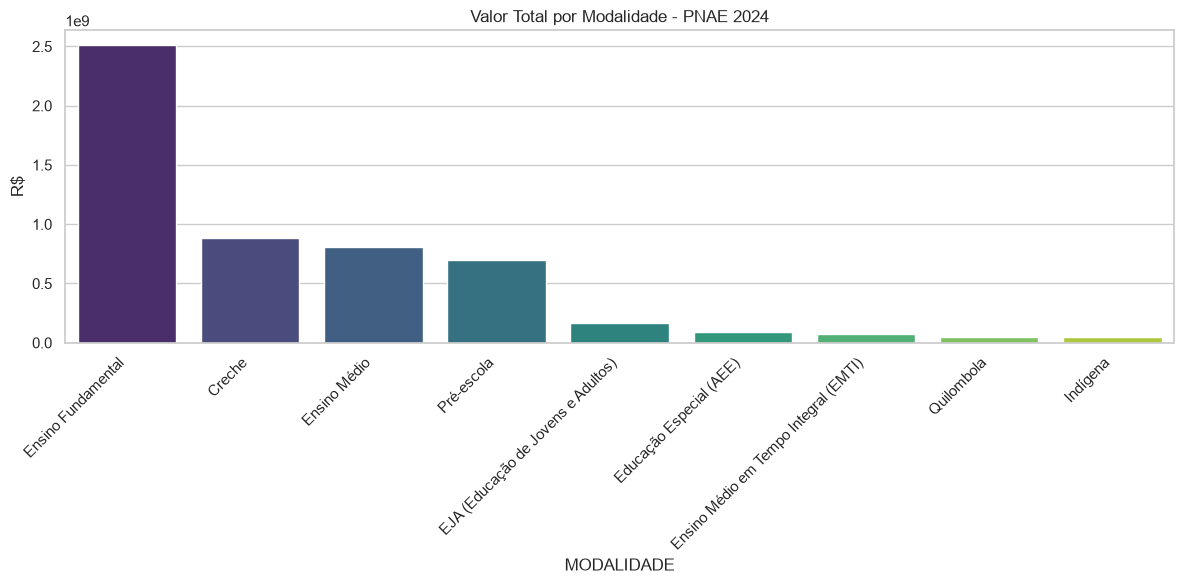

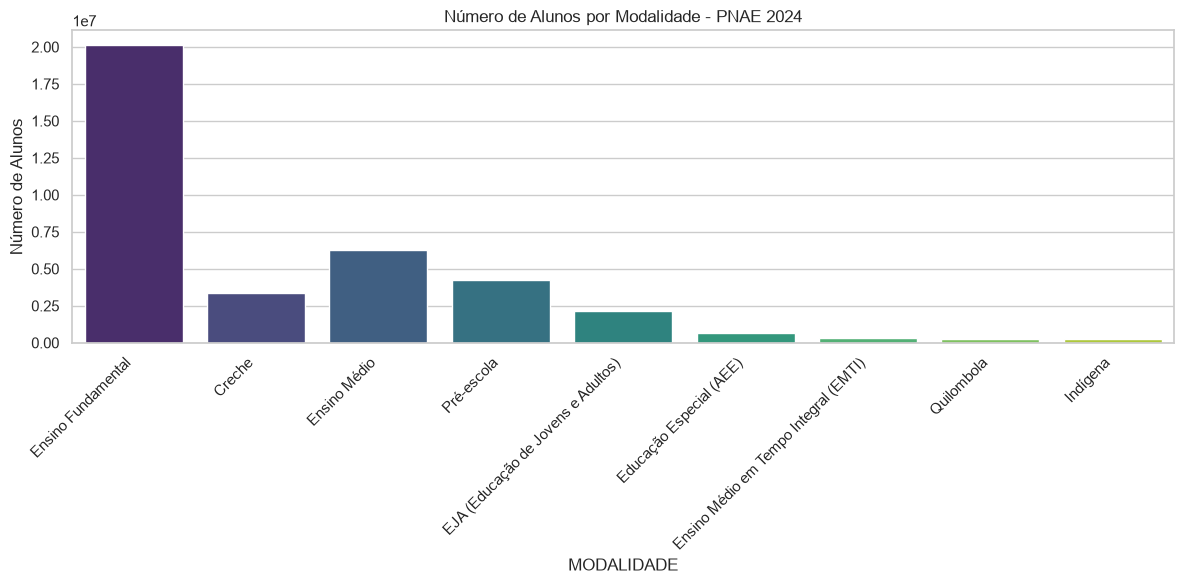

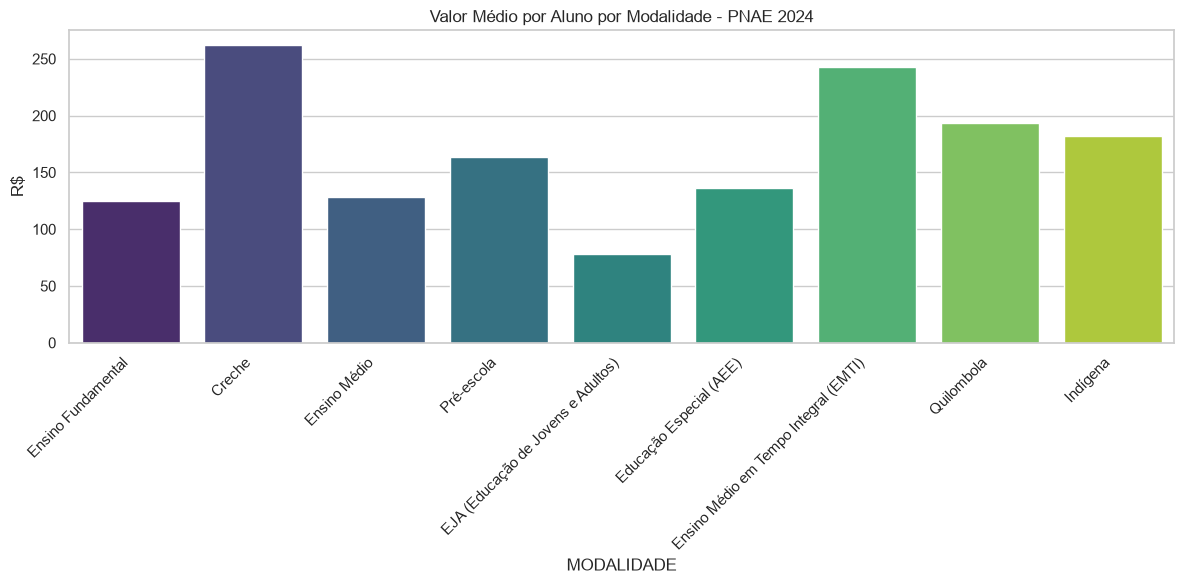

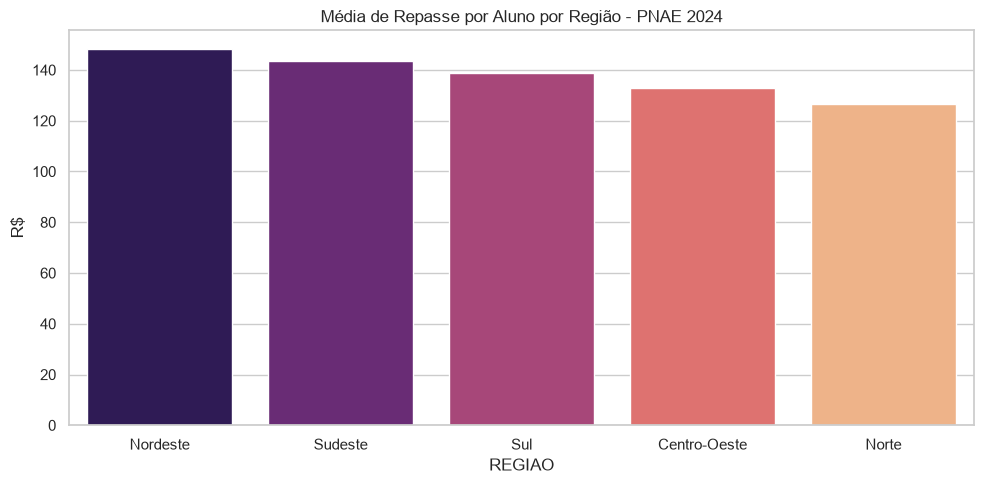

In [18]:
# E agora, vamos gerar os gráficos para visualização dos dados

import matplotlib.pyplot as plt
import seaborn as sns

# Configurando estilo
sns.set_theme(style="whitegrid")

# 1. Lendo os dados salvos para exibir
df_mod = pd.read_csv('dados/analise_1.csv')
df_reg = pd.read_csv('dados/analise_2.csv')

# 2. Gráficos por Modalidade

# Pergunta 1:
plt.figure(figsize=(12, 6))
sns.barplot(data=df_mod, x='MODALIDADE', y='valor_total_por_modalidade', palette='viridis', hue='MODALIDADE', legend=False)
plt.title('Valor Total por Modalidade - PNAE 2024')
plt.xticks(rotation=45, ha='right')
plt.ylabel('R$')
plt.tight_layout()
plt.show()

#Gráfico de numero de alunos por modalidade, para auxiliar a resposta da pergunta 3:
plt.figure(figsize=(12, 6))
sns.barplot(data=df_mod, x='MODALIDADE', y='numero_alunos_por_modalidade', palette='viridis', hue='MODALIDADE', legend=False)
plt.title('Número de Alunos por Modalidade - PNAE 2024')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Número de Alunos')
plt.tight_layout()
plt.show()


#Pergunta 2 e 3:
plt.figure(figsize=(12, 6))
sns.barplot(data=df_mod, x='MODALIDADE', y='valor_medio_aluno_por_modalidade', palette='viridis', hue='MODALIDADE', legend=False)
plt.title('Valor Médio por Aluno por Modalidade - PNAE 2024')
plt.xticks(rotation=45, ha='right')
plt.ylabel('R$')
plt.tight_layout()
plt.show()

# 3. Gráfico por Região
#Pergunta 4:
plt.figure(figsize=(10, 5))
sns.barplot(data=df_reg, x='REGIAO', y='valor_medio_aluno_por_regiao', palette='magma', hue='REGIAO', legend=False)
plt.title('Média de Repasse por Aluno por Região - PNAE 2024')
plt.ylabel('R$')
plt.tight_layout()
plt.show()